In [36]:
import os
from urllib.request import urlretrieve
import gzip
import matplotlib.pyplot as plt
import numpy as np
from pyteomics import fasta, parser, mass, achrom, electrochem, auxiliary
import pandas as pd
import matplotlib.pyplot as plt
counter = 0

# with gzip.open('/home/callum/human_proteome/proteome.gz', mode='rt') as gzfile:
#     for description, sequence in fasta.FASTA(gzfile):
#         counter += 1
#         print(description, sequence)
#         if counter == 5:
#             break
#10.126.227.117








# def tryptic_cleavage(fasta_path, n, residue, missed_cleavages=0):
#     id_dict = {}
#     all_peptides = set()
#     with open(fasta_path, mode='rt') as f:
#         for description, sequence in fasta.FASTA(f):
#             acc = description.strip().split("|")[1]
#             peps = parser.cleave(sequence, 'trypsin', missed_cleavages=missed_cleavages)
#             short = {p for p in peps if len(p) < n and residue in p}
#             id_dict[acc] = sorted(short)
#             all_peptides.update(short)
#     print(f"Done, {len(all_peptides)} unique short peptides")
#     return all_peptides, id_dict


# pep, ids  = tryptic_cleavage(out_fasta, 6, "C", 0)

# for keys, values in ids.items():
#     if values != []:
#         print(keys,values)



In [2]:
# create fasta file here based on the chosen df

out_fasta = "/home/callum/sno_data/processed/P03372.fasta"
input_file = '/home/callum/sno_data/processed/pcys/pcys_org.csv'

#wanted = df[df["organism"] == "Homo sapiens"]

def get_id_list(type = "df", input_path = None, lst = None):
    if type == "df":
        df = pd.read_csv(input_path) 
        wanted = set(df['id'].dropna().astype(str).str.strip())
    elif type == "lst":
        wanted = set(lst)
    return wanted

# example of df path
x = get_id_list("df", input_file, lst = None)
# print(x)
#example of list
# x = get_id_list("lst", lst = ["P03372"])

# print(x)
#wanted = "P03372"

def accession(description):
    # 'sp|P03372|ESR1_HUMAN Estrogen receptor ...' -> 'P03372'
    return description.split('|')[1]

def return_fasta(wanted, input_path, output_path):
	found = set()

	with gzip.open('/home/callum/human_proteome/proteome.gz', mode='rt') as gzfile:
		subset = []
		for description, sequence in fasta.FASTA(gzfile):
			acc = accession(description)
			if acc in wanted:
				subset.append((description, sequence))
				found.add(acc)

	fasta.write(subset, f'{output_path}')

	missing = wanted - found
	print(f"{len(found)} found, {len(missing)} not in proteome")
 
 

return_fasta(x, "/home/callum/sno_data/processed/dn/dn_test_org.csv", out_fasta)


4567 found, 10 not in proteome


In [22]:
df = pd.read_csv(input_file)

def undetected_cys_positions(fasta_path, n_min, n_max, residue="C", missed_cleavages=2):
    """{uniprot_id: [{'pos': 1-based, 'peptide': seq, 'type': 'short'|'long'}, ...]}"""
    out = {}
    with open(fasta_path, mode='rt') as f:
        for description, sequence in fasta.FASTA(f):
            acc = description.strip().split("|")[1]
            hits = []
            for start, pep in parser.icleave(sequence, 'trypsin', missed_cleavages=missed_cleavages):
                if residue not in pep:
                    continue
                if len(pep) < n_min:
                    kind = 'short'
                elif len(pep) > n_max:
                    kind = 'long'
                else:
                    continue
                for i, aa in enumerate(pep):
                    if aa == residue:
                        hits.append({'pos': start + i + 1, 'peptide': pep, 'type': kind})
            out[acc] = hits
    return out

# modify here
undetected = undetected_cys_positions(out_fasta, 2, 50, "C", 0)
# modified positions per protein (ints, 1-based assumed)
mod = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
         .groupby("id")["position"].apply(set))

conflicts = []
n_undt_cys = 0
for acc, hits in undetected.items():
    n_undt_cys += len(hits)
    mod_pos = mod.get(acc, set())
    for h in hits:
        if h['pos'] in mod_pos:
            conflicts.append({'id': acc, 'position': h['pos'], 'peptide': h['peptide'], 'type': h['type']})




conflict_df = pd.DataFrame(conflicts, columns=['id', 'position', 'peptide', 'type'])

all_hits = [dict(h, id=acc) for acc, hits in undetected.items() for h in hits]
hits_df = pd.DataFrame(all_hits, columns=['id', 'pos', 'peptide', 'type'])

print(hits_df["type"].value_counts())
print(conflict_df["type"].value_counts())




with open(out_fasta) as f:
    seqs = {d.split("|")[1]: s for d, s in fasta.FASTA(f)}


rows = []
for acc, seq in seqs.items():
    hits = undetected.get(acc, [])
    rows.append({
        "id": acc,
        "total_cys": seq.count("C"),
        "short": sum(h["type"] == "short" for h in hits),
        "long": sum(h["type"] == "long" for h in hits),
    })

prot = pd.DataFrame(rows)
prot = prot[prot["total_cys"] > 0].copy()          # avoid dividing by zero
prot["pct_short"] = 100 * prot["short"] / prot["total_cys"]
prot["pct_long"] = 100 * prot["long"] / prot["total_cys"]
prot["pct_lost"] = prot["pct_short"] + prot["pct_long"]

print(prot[["pct_short", "pct_long", "pct_lost"]].describe().round(2))         # mean, median, quartiles
pooled = 100 * (prot["short"].sum() + prot["long"].sum()) / prot["total_cys"].sum()
print(f"pooled % lost: {pooled:.2f}")


print("###############")

# proteins with at least one lost Cys of each type
print((prot["short"] > 0).sum(), (prot["long"] > 0).sum(), ((prot["short"] + prot["long"]) > 0).sum())

# total lost Cys of each type
print(prot["short"].sum(), prot["long"].sum())


def peptide_counts(fasta_path, n_min, n_max, residue="C", missed_cleavages=2, require_residue=True):
    total = short = long = 0
    with open(fasta_path, mode='rt') as f:
        for description, sequence in fasta.FASTA(f):
            for start, pep in parser.icleave(sequence, 'trypsin', missed_cleavages=missed_cleavages):
                if require_residue and residue not in pep:
                    continue
                total += 1
                if len(pep) < n_min:
                    short += 1
                elif len(pep) > n_max:
                    long += 1
    return total, short, long

# valid modified sites (position must be a Cys in the sequence)
sites = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
           .drop_duplicates(["id", "position"]))
sites = sites[sites["id"].isin(seqs)]
sites = sites[[0 < p <= len(seqs[i]) and seqs[i][p - 1] == "C"
               for i, p in zip(sites["id"], sites["position"])]]
n_mod = len(sites)

total_cys = int(prot["total_cys"].sum())
lost_short = int((hits_df["type"] == "short").sum())
lost_long = int((hits_df["type"] == "long").sum())
lost_cys = lost_short + lost_long
n_conf_short = int((conflict_df["type"] == "short").sum())
n_conf_long = int((conflict_df["type"] == "long").sum())
n_conf = n_conf_short + n_conf_long

print("---------- peptide level ----------")
print(f"Cys-containing peptides: {total}")
print(f"  short: {short_n} ({100*short_n/total:.2f}%)  long: {long_n} ({100*long_n/total:.2f}%)")
print(f"  total lost: {short_n + long_n} ({100*(short_n + long_n)/total:.2f}%)")

print("---------- site (Cys) level ----------")
print(f"total Cys: {total_cys}")
print(f"  lost short: {lost_short} ({100*lost_short/total_cys:.2f}%)  lost long: {lost_long} ({100*lost_long/total_cys:.2f}%)")
print(f"  total lost: {lost_cys} ({100*lost_cys/total_cys:.2f}%)")
print(f"modified sites (valid Cys): {n_mod}")
print(f"  in lost peptides (conflicts): {n_conf} (short {n_conf_short}, long {n_conf_long})")
print(f"  = {100*n_conf/n_mod:.2f}% of modified sites, {100*n_conf/lost_cys:.2f}% of lost Cys")

neg_total = total_cys - n_mod
neg_lost = lost_cys - n_conf
print(f"negatives: {neg_total}, lost negatives: {neg_lost} ({100*neg_lost/neg_total:.2f}%)")

type
long     2683
short       9
Name: count, dtype: int64
type
long     15
short     1
Name: count, dtype: int64
       pct_short  pct_long  pct_lost
count    4567.00   4567.00   4567.00
mean        0.04      3.29      3.33
std         1.00      8.60      8.65
min         0.00      0.00      0.00
25%         0.00      0.00      0.00
50%         0.00      0.00      0.00
75%         0.00      0.00      0.00
max        50.00     80.00     80.00
pooled % lost: 4.43
###############
9 930 938
9 2683
---------- peptide level ----------
Cys-containing peptides: 48016
  short: 3779 (7.87%)  long: 1273 (2.65%)
  total lost: 5052 (10.52%)
---------- site (Cys) level ----------
total Cys: 60780
  lost short: 9 (0.01%)  lost long: 2683 (4.41%)
  total lost: 2692 (4.43%)
modified sites (valid Cys): 11645
  in lost peptides (conflicts): 16 (short 1, long 15)
  = 0.14% of modified sites, 0.59% of lost Cys
negatives: 49135, lost negatives: 2676 (5.45%)


In [23]:
rows = []
for kind in ["short", "long"]:
    lost = int((hits_df["type"] == kind).sum())
    conf = int((conflict_df["type"] == kind).sum())
    rows.append({"type": kind, "total_lost": lost, "conflicts": conf, "final_lost": lost - conf})

tbl = pd.DataFrame(rows).set_index("type")
tbl.loc["all"] = tbl.sum()

# percentages: total_lost and conflicts as share of all Cys / modified sites; final as share of negatives
tbl["pct_of_all_cys"] = (100 * tbl["total_lost"] / total_cys).round(2)
tbl["conflicts_pct_of_modified"] = (100 * tbl["conflicts"] / n_mod).round(2)
tbl["final_pct_of_negatives"] = (100 * tbl["final_lost"] / neg_total).round(2)

print(tbl)
print(f"total Cys: {total_cys} | modified sites: {n_mod} | negatives: {neg_total}")

       total_lost  conflicts  final_lost  pct_of_all_cys  \
type                                                       
short           9          1           8            0.01   
long         2683         15        2668            4.41   
all          2692         16        2676            4.43   

       conflicts_pct_of_modified  final_pct_of_negatives  
type                                                      
short                       0.01                    0.02  
long                        0.13                    5.43  
all                         0.14                    5.45  
total Cys: 60780 | modified sites: 11645 | negatives: 49135


In [ ]:
N_MAX = 50

# 1. valid modified sites (position must be a Cys in the sequence)
with open(out_fasta) as f:
    seqs = {d.split("|")[1]: s for d, s in fasta.FASTA(f)}

sites = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
           .drop_duplicates(["id", "position"]))
sites = sites[sites["id"].isin(seqs)]
sites = sites[[0 < p <= len(seqs[i]) and seqs[i][p - 1] == "C"
               for i, p in zip(sites["id"], sites["position"])]]
mod_set = set(zip(sites["id"], sites["position"]))

# 2. digest once: every Cys with the length of the peptide it sits in
records = []
for acc, seq in seqs.items():
    for start, pep in parser.icleave(seq, "trypsin", missed_cleavages=0):
        if "C" not in pep:
            continue
        for i, aa in enumerate(pep):
            if aa == "C":
                records.append((acc, start + i + 1, len(pep)))

cys_df = pd.DataFrame(records, columns=["id", "pos", "pep_len"])
cys_df["is_mod"] = [(i, p) in mod_set for i, p in zip(cys_df["id"], cys_df["pos"])]

# 3. loop over n_min
rows = []
for n in range(2, 9):
    short = cys_df[cys_df["pep_len"] < n]
    long_ = cys_df[cys_df["pep_len"] > N_MAX]
    s_lost, s_conf = len(short), int(short["is_mod"].sum())
    l_lost, l_conf = len(long_), int(long_["is_mod"].sum())
    rows.append({
        "limit_n": n,
        "short_identified_lost": s_lost,
        "short_conflicts": s_conf,
        "short_total_lost": s_lost - s_conf,
        "long_identified_lost": l_lost,
        "long_conflicts": l_conf,
        "long_total_lost": l_lost - l_conf,
    })

n_table = pd.DataFrame(rows).set_index("limit_n")
print(n_table)
print(f"total Cys: {len(cys_df)} | modified sites (valid Cys): {len(sites)}")

82 sites dropped (not a Cys at the stated position)
       pct_neg_short  pct_neg_long  pct_neg_lost
count        4193.00       4193.00       4193.00
mean            0.06          4.59          4.65
std             1.88         12.08         12.25
min             0.00          0.00          0.00
25%             0.00          0.00          0.00
50%             0.00          0.00          0.00
75%             0.00          0.00          0.00
max           100.00        100.00        100.00
pooled % of negatives lost: 5.45
negatives total: 49135, lost: 2676
---------- peptide level ----------
Cys-containing peptides: 48016
  short: 3779 (7.87%)  long: 1273 (2.65%)
  total lost: 5052 (10.52%)
---------- site (Cys) level ----------
total Cys: 60780
  lost short: 9 (0.01%)  lost long: 2683 (4.41%)
  total lost: 2692 (4.43%)
modified sites (valid Cys): 11645
  in lost peptides (conflicts): 16 (short 1, long 15)
  = 0.14% of modified sites, 0.59% of lost Cys
negatives: 49135, lost negatives: 2

In [17]:
def peptide_counts(fasta_path, n_min, n_max, residue="C", missed_cleavages=2, require_residue=True):
    total = short = long = 0
    with open(fasta_path, mode='rt') as f:
        for description, sequence in fasta.FASTA(f):
            for start, pep in parser.icleave(sequence, 'trypsin', missed_cleavages=missed_cleavages):
                if require_residue and residue not in pep:
                    continue
                total += 1
                if len(pep) < n_min:
                    short += 1
                elif len(pep) > n_max:
                    long += 1
    return total, short, long

# valid modified sites (position must be a Cys in the sequence)
sites = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
           .drop_duplicates(["id", "position"]))
sites = sites[sites["id"].isin(seqs)]
sites = sites[[0 < p <= len(seqs[i]) and seqs[i][p - 1] == "C"
               for i, p in zip(sites["id"], sites["position"])]]
n_mod = len(sites)

total_cys = int(prot["total_cys"].sum())
lost_short = int((hits_df["type"] == "short").sum())
lost_long = int((hits_df["type"] == "long").sum())
lost_cys = lost_short + lost_long
n_conf_short = int((conflict_df["type"] == "short").sum())
n_conf_long = int((conflict_df["type"] == "long").sum())
n_conf = n_conf_short + n_conf_long

print("---------- peptide level ----------")
print(f"Cys-containing peptides: {total}")
print(f"  short: {short_n} ({100*short_n/total:.2f}%)  long: {long_n} ({100*long_n/total:.2f}%)")
print(f"  total lost: {short_n + long_n} ({100*(short_n + long_n)/total:.2f}%)")

print("---------- site (Cys) level ----------")
print(f"total Cys: {total_cys}")
print(f"  lost short: {lost_short} ({100*lost_short/total_cys:.2f}%)  lost long: {lost_long} ({100*lost_long/total_cys:.2f}%)")
print(f"  total lost: {lost_cys} ({100*lost_cys/total_cys:.2f}%)")
print(f"modified sites (valid Cys): {n_mod}")
print(f"  in lost peptides (conflicts): {n_conf} (short {n_conf_short}, long {n_conf_long})")
print(f"  = {100*n_conf/n_mod:.2f}% of modified sites, {100*n_conf/lost_cys:.2f}% of lost Cys")

neg_total = total_cys - n_mod
neg_lost = lost_cys - n_conf
print(f"negatives: {neg_total}, lost negatives: {neg_lost} ({100*neg_lost/neg_total:.2f}%)")

---------- peptide level ----------
Cys-containing peptides: 48016
  short: 3779 (7.87%)  long: 1273 (2.65%)
  total lost: 5052 (10.52%)
---------- site (Cys) level ----------
total Cys: 60780
  lost short: 2155 (3.55%)  lost long: 2683 (4.41%)
  total lost: 4838 (7.96%)
modified sites (valid Cys): 11645
  in lost peptides (conflicts): 94 (short 79, long 15)
  = 0.81% of modified sites, 1.94% of lost Cys
negatives: 49135, lost negatives: 4744 (9.66%)


In [28]:
df = pd.read_csv('/home/callum/sno_data/processed/dn/dn_test_org.csv')  # or however you load it
mask = df["id"] == "O75369"
sub = df[mask]

print(sub)

        id  position      organism
42  O75369      2501  Homo sapiens
43  O75369       706  Homo sapiens
44  O75369      2431  Homo sapiens


In [16]:
df = pd.read_csv("/home/callum/sno_data/processed/pcys/pcys_org.csv")  # or however you load it

print(df.shape)

(11750, 3)


In [29]:
N_MAX = 50

# 1. valid modified sites (position must be a Cys in the sequence)
with open(out_fasta) as f:
    seqs = {d.split("|")[1]: s for d, s in fasta.FASTA(f)}

sites = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
           .drop_duplicates(["id", "position"]))
sites = sites[sites["id"].isin(seqs)]
sites = sites[[0 < p <= len(seqs[i]) and seqs[i][p - 1] == "C"
               for i, p in zip(sites["id"], sites["position"])]]
mod_set = set(zip(sites["id"], sites["position"]))

# 2. digest once: every Cys with the length of the peptide it sits in
records = []
for acc, seq in seqs.items():
    for start, pep in parser.icleave(seq, "trypsin", missed_cleavages=0):
        if "C" not in pep:
            continue
        for i, aa in enumerate(pep):
            if aa == "C":
                records.append((acc, start + i + 1, len(pep)))

cys_df = pd.DataFrame(records, columns=["id", "pos", "pep_len"])
cys_df["is_mod"] = [(i, p) in mod_set for i, p in zip(cys_df["id"], cys_df["pos"])]

# 3. loop over n_min
rows = []
for n in range(2, 12):
    short = cys_df[cys_df["pep_len"] < n]
    long_ = cys_df[cys_df["pep_len"] > N_MAX]
    s_lost, s_conf = len(short), int(short["is_mod"].sum())
    l_lost, l_conf = len(long_), int(long_["is_mod"].sum())
    rows.append({
        "limit_n": n,
        "short_identified_lost": s_lost,
        "short_conflicts": s_conf,
        "short conflicts (%)": round((100 * s_conf / s_lost if s_lost else 0), 2),
        "short_total_lost": s_lost - s_conf,
        "long_identified_lost": l_lost,
        "long_conflicts": l_conf,
        "long_total_lost": l_lost - l_conf,
    })

n_table = pd.DataFrame(rows).set_index("limit_n")
print(n_table)
print(f"total Cys: {len(cys_df)} | modified sites (valid Cys): {len(sites)}")

         short_identified_lost  short_conflicts  short conflicts (%)  \
limit_n                                                                
2                            9                1                11.11   
3                          738               36                 4.88   
4                         2155               79                 3.67   
5                         3834              133                 3.47   
6                         5719              228                 3.99   
7                         8009              545                 6.80   
8                        10417             1148                11.02   
9                        12891             1873                14.53   
10                       15485             2685                17.34   
11                       18029             3468                19.24   

         short_total_lost  long_identified_lost  long_conflicts  \
limit_n                                                           
2

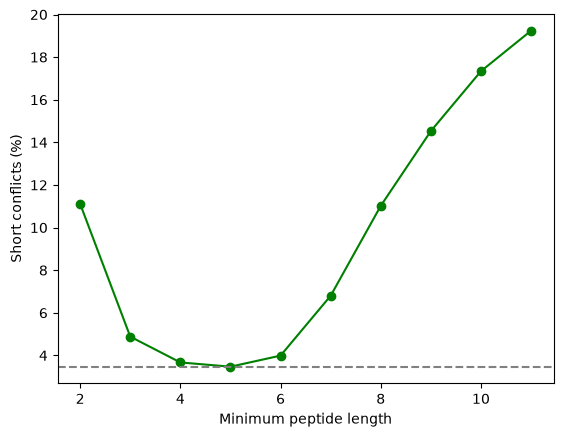

<Figure size 640x480 with 0 Axes>

In [59]:
y = n_table["short conflicts (%)"]
y = y.to_numpy()
x = n_table.index.to_numpy()

x2 = range(2, len(x))
y2 = np.array([3.47, 3.47, 3.47, 3.47, 3.47, 3.47, 3.47, 3.47])

plt.plot(x, y, marker="o", color = "green")
plt.axhline(3.47, linestyle="--", color="grey")
plt.xlabel("Minimum peptide length")
plt.ylabel("Short conflicts (%)")
plt.show()

plt.savefig("../images/percentages.png")


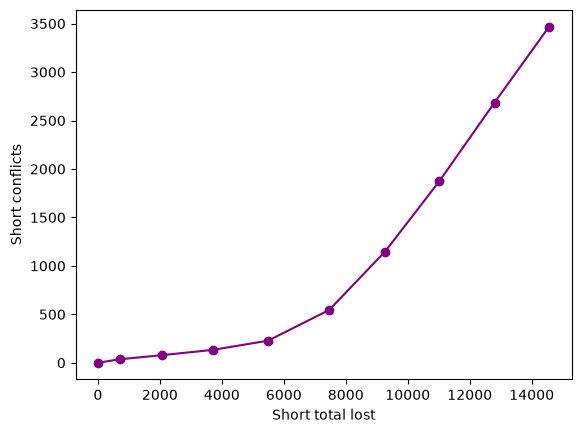

<Figure size 640x480 with 0 Axes>

In [60]:
y = n_table["short_conflicts"]
y = y.to_numpy()
x = n_table["short_total_lost"]

plt.plot(x,y, marker="o", color = "purple")
plt.xlabel("Short total lost")
plt.ylabel("Short conflicts")
plt.show()
plt.savefig("../images/counts.png", dpi=200, bbox_inches="tight")

In [25]:
with open(out_fasta) as f:
    seqs = {d.split("|")[1]: s for d, s in fasta.FASTA(f)}

# valid modified sites: deduplicated, and the position must be a Cys in the sequence
sites = (df.assign(id=df["id"].astype(str).str.strip(), position=df["position"].astype(int))
           .drop_duplicates(["id", "position"]))
sites = sites[sites["id"].isin(seqs)]
sites = sites[[0 < p <= len(seqs[i]) and seqs[i][p - 1] == "C"
               for i, p in zip(sites["id"], sites["position"])]]

# per protein
per_prot = pd.DataFrame({"id": list(seqs), "total_cys": [s.count("C") for s in seqs.values()]})
per_prot["modified"] = per_prot["id"].map(sites.groupby("id").size()).fillna(0).astype(int)
per_prot = per_prot[per_prot["total_cys"] > 0].copy()
per_prot["pct_modified"] = 100 * per_prot["modified"] / per_prot["total_cys"]

# pooled
total_cys = per_prot["total_cys"].sum()
n_mod = per_prot["modified"].sum()
print(f"total Cys: {total_cys} | modified: {n_mod}")
print(f"pooled % of Cys modified: {100 * n_mod / total_cys:.2f}")

# distribution across proteins
print(per_prot["pct_modified"].describe().round(2))

total Cys: 60780 | modified: 11645
pooled % of Cys modified: 19.16
count    4567.00
mean       32.51
std        28.07
min         0.00
25%        11.11
50%        24.32
75%        50.00
max       100.00
Name: pct_modified, dtype: float64


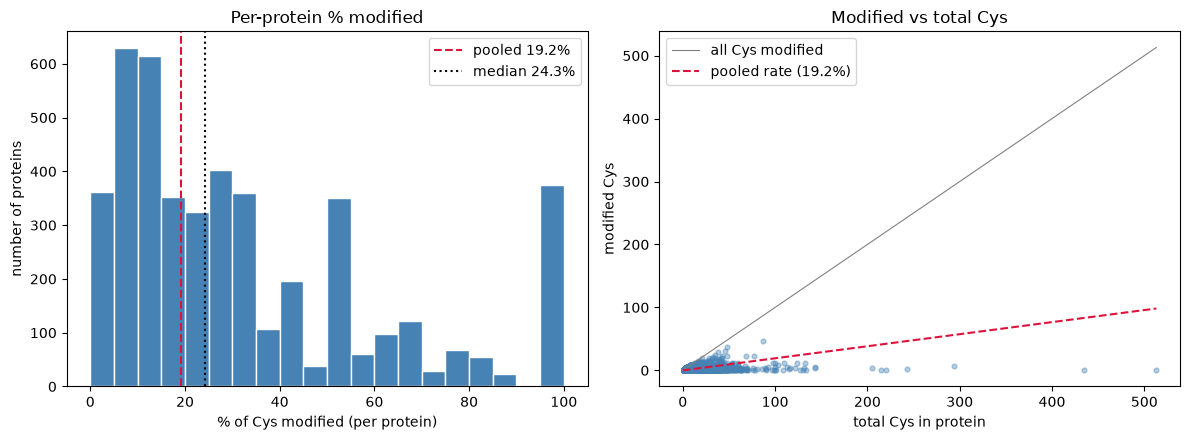

In [26]:
import numpy as np
import matplotlib.pyplot as plt

pooled_pct = 100 * per_prot["modified"].sum() / per_prot["total_cys"].sum()
median_pct = per_prot["pct_modified"].median()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# left: distribution of per-protein % modified
ax = axes[0]
ax.hist(per_prot["pct_modified"], bins=np.arange(0, 105, 5), color="steelblue", edgecolor="white")
ax.axvline(pooled_pct, color="crimson", linestyle="--", label=f"pooled {pooled_pct:.1f}%")
ax.axvline(median_pct, color="black", linestyle=":", label=f"median {median_pct:.1f}%")
ax.set_xlabel("% of Cys modified (per protein)")
ax.set_ylabel("number of proteins")
ax.set_title("Per-protein % modified")
ax.legend()

# right: modified vs total Cys
ax = axes[1]
ax.scatter(per_prot["total_cys"], per_prot["modified"], s=12, alpha=0.4, color="steelblue")
mx = per_prot["total_cys"].max()
ax.plot([0, mx], [0, mx], color="grey", linewidth=0.8, label="all Cys modified")
ax.plot([0, mx], [0, mx * pooled_pct / 100], color="crimson", linestyle="--", label=f"pooled rate ({pooled_pct:.1f}%)")
ax.set_xlabel("total Cys in protein")
ax.set_ylabel("modified Cys")
ax.set_title("Modified vs total Cys")
ax.legend()

plt.tight_layout()
plt.savefig("pct_modified.png", dpi=200)
plt.show()